# Project

### Group L : Taïs Thomas, Marouchka Heck, Marie-Caroline Bilocq

### Question 1
Compute the density ($g.cm^{-3}$), accessible surface area - ASA ($A^2$), accessible probe-occupiable volume - POAV ($A^3$) and porosity of the different structures by running pore analysis.

We first characterize the pore properties of the five MOF structures: Mg-MOF-74, NOTT-300, UTSA-20, UTSA-80 and ZIF-8.
For each structure, we compute the density, accessible surface area (ASA), accessible probe-occupiable volume (POAV), and porosity using Zeo++.
A probe radius of 1.525 Å is used.

| Structure | Density ($g.cm^{-3}$) | ASA ($A^2$) | POAV ($A^3$) | Porosity |
|---|---:|---:|---:|---:|
| Mg-MOF-74 | 0.886275 | 222.828 | 837.198 | 0.61368 |
| NOTT-300 | 1.03926 | 453.452 | 1297.11 | 0.48999 |
| UTSA-20 | 0.882399 | 1307.51 | 3575.36 | 0.62907 |
| UTSA-80 | 0.678215 | 3114.62 | 9619.78 | 0.66798 |
| ZIF-8 | 0.909567 | 1482.95 | 2770.55 | 0.55568 |

For the porosity, we use the POAV volume fraction, since it represents the fraction of the unit-cell volume that is accessible to the probe used in the pore analysis.

Among the five structures, UTSA-80 has the lowest density and the highest ASA, POAV and porosity. UTSA-20 also shows a relatively high porosity, followed by Mg-MOF-74, ZIF-8 and NOTT-300. NOTT-300 has the highest density and the lowest porosity of the structures considered.

### Question 2
Compute the Henry coefficients for $CO_2$ and $N_2$ at 25°C. Rank the structures based on their affinity for $CO_2$.

The Henry coefficients $K_H$ of $CO_2$ and $N_2$ were computed at 298 K for each MOF.

| Structure | $K_H$ for $CO_2$ ($mol \cdot kg^{-1} \cdot Pa^{-1}$)|$K_H$ for $N_2$ ($mol \cdot kg^{-1} \cdot Pa^{-1}$)|
|---|---:|---:|
| Mg-MOF-74 |8.41724 × $10^{-5}$ | 3.34155 × $10^{-6}$ |
| NOTT-300 | 1.84886 × $10^{-4}$ | 1.05363 × $10^{-5}$ |
| UTSA-20 | mc | mc |
| UTSA-80 | mc | mc |
| ZIF-8 | 8.81558 × $10^{-6}$ | NONE |

<table>
  <thead>
    <tr>
      <th rowspan="2">Structure</th>
      <th colspan="2">Henry coefficient, K<sub>H</sub> (mol kg<sup>-1</sup> Pa<sup>-1</sup>)</th>
    </tr>
    <tr>
      <th>for CO<sub>2</sub></th>
      <th>for N<sub>2</sub></th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>Mg-MOF-74</td>
      <td>8.50464 × 10<sup>-5</sup></td>
      <td>3.32929 × 10<sup>-6</sup></td>
    </tr>
    <tr>
      <td>NOTT-300</td>
      <td>1.84219 × 10<sup>-5</sup></td>
      <td>1.05346 × 10<sup>-5</sup></td>
    </tr>
    <tr>
      <td>UTSA-20</td>
      <td>mc</td>
      <td>mc</td>
    </tr>
    <tr>
      <td>UTSA-80</td>
      <td>mc</td>
      <td>mc</td>
    </tr>
    <tr>
      <td>ZIF-8</td>
      <td>mouka </td>
      <td>mouka</td>
    </tr>
  </tbody>
</table>

### Question 3
Compute $CO_2$ and $N_2$ pure component isotherms at 25°C for the given structures. Plot the pure isotherms per molecule.

Pure-component $CO_2$ and $N_2$ adsorption isotherms were computed at 298 K for each framework using Grand Canonical Monte Carlo (GCMC) simulations with RASPA. In GCMC, the framework is in equilibrium with an imaginary gas reservoir at fixed temperature $T$ and chemical potential $\mu$. The number of guest molecules in the pores fluctuates through random insertion, deletion and displacement moves, accepted or rejected according to the energy change given by the force field. The average number of molecules in the box gives the loading $q$ (mol/kg) at each pressure.

The loading is plotted against pressure (bar). Two figures are shown, one for $CO_2$ and one for $N_2$, each comparing the isotherms of the five structures.

In [ ]:
import os
import pandas as pd

def read(f):
    return pd.read_csv(f) if os.path.exists(f) else None

mgMOF74_co2 = read("Mg-MOF-74_CO2.csv")
mgMOF74_n2  = read("Mg-MOF-74_N2.csv")

nott300_co2 = read("NOTT-300_CO2.csv")
nott300_n2  = read("NOTT-300_N2.csv")

utsa20_co2 = read("UTSA-20_CO2.csv")
utsa20_n2  = read("UTSA-20_N2.csv")

utsa80_co2 = read("UTSA-80_CO2.csv")
utsa80_n2  = read("UTSA-80_N2.csv")

zif8_co2 = read("ZIF-8_CO2.csv")
zif8_n2  = read("ZIF-8_N2.csv")

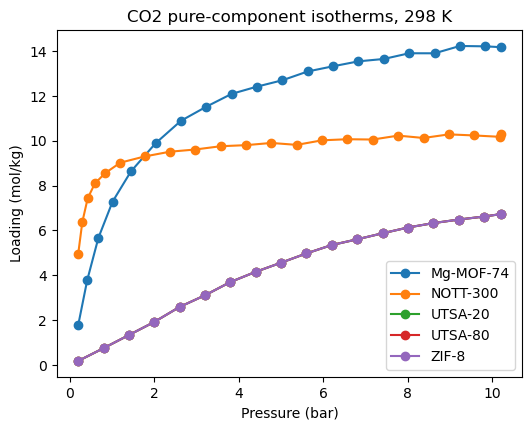

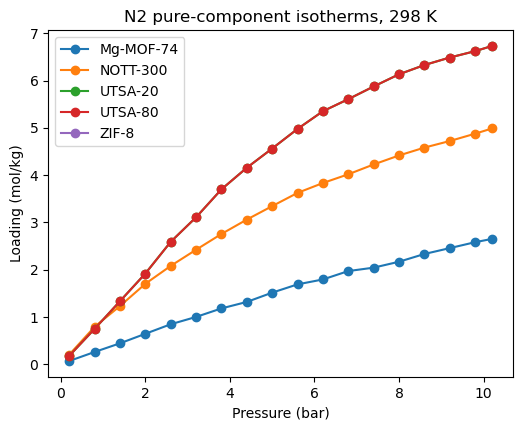

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import ast

P_TO_BAR = 1.0  

co2 = {"Mg-MOF-74": mgMOF74_co2, "NOTT-300": nott300_co2,
       "UTSA-20": utsa20_co2, "UTSA-80": utsa80_co2, "ZIF-8": zif8_co2}
n2  = {"Mg-MOF-74": mgMOF74_n2, "NOTT-300": nott300_n2,
       "UTSA-20": utsa20_n2, "UTSA-80": utsa80_n2, "ZIF-8": zif8_n2}

def isotherm(df):
    kv = dict(zip(df["Key"], df["Value"]))
    iso = kv.get("isotherm")
    if not isinstance(iso, str):  
        return np.array([]), np.array([])
    iso = ast.literal_eval(iso)

    p = np.array(iso["pressure"], float) * P_TO_BAR     # bar
    key = next(k for k in iso if "loading" in k.lower() and "dev" not in k.lower()
               and "unit" not in k.lower())
    q = np.array(iso[key], float)
    units = [str(v) for k, v in iso.items() if "unit" in k.lower()]
    if any("molec" in u.lower() for u in units):
        q = q * float(kv["conversion_factor_molec_uc_to_mol_kg"])

    order = np.argsort(p)
    return p[order], q[order]

for gas, series in (("CO2", co2), ("N2", n2)):
    fig, ax = plt.subplots(figsize=(6, 4.5))
    for name, df in series.items():
        if df is None:
            continue
        p, q = isotherm(df)
        ax.plot(p, q, "o-", label=name)
    ax.set_xlabel("Pressure (bar)")
    ax.set_ylabel("Loading (mol/kg)")
    ax.set_title(f"{gas} pure-component isotherms, 298 K")
    ax.legend()
    plt.show()

**At low pressure the loading is proportional to the Henry coefficient, so the CO₂ ordering follows Question 2: NOTT-300 > Mg-MOF-74 > ZIF-8 (UTSA-20 and UTSA-80 to be added). For each structure, CO₂ is adsorbed much more strongly than N₂, because CO₂ has a quadrupole moment that interacts with the partial charges of the framework, whereas N₂ interacts mainly through dispersion. No N₂ isotherm is obtained for ZIF-8: the N₂ probe is too large to pass the narrow windows of the rigid structure (POAV = 0), so the cages are treated as inaccessible.**

### Question 4
Calculate the $CO_2$ working capacity (WC) for the different structures.

In a PSA/VSA process, the adsorbent is loaded with $CO_2$ at high pressure (adsorption) and then regenerated by lowering the pressure (desorption). The working capacity is the amount of $CO_2$ that is actually recovered during one cycle:

$$WC = q(P_{ads}) - q(P_{des})$$

where:
- $q(P_{ads})$ is the $CO_2$ loading (mol/kg) at the adsorption pressure, the amount captured from the flue gas.
- $q(P_{des})$ is the loading that remains at the desorption pressure, the $CO_2$ that stays in the pores and is not released.

Here the working capacity is estimated from the equilibrium isotherms of Question 3, without simulating the process itself. $P_{ads}$ is taken as the total flue-gas pressure (1 bar) and $P_{des} = 0.2$ bar is the desorption pressure, both at 298 K. The loadings are linearly interpolated between the simulated pressures.

In [15]:
P_ADS, P_DES = 1.0, 0.2  

rows = []
for name, df in co2.items():
    if df is None:
        rows.append((name, np.nan, np.nan, np.nan))
        continue
    p, q = isotherm(df)
    if p.size == 0:
        rows.append((name, np.nan, np.nan, np.nan))
        continue
    q_ads, q_des = np.interp([P_ADS, P_DES], p, q)
    rows.append((name, q_ads, q_des, q_ads - q_des))

wc = pd.DataFrame(rows, columns=["Structure", "q_ads (mol/kg)",
                                 "q_des (mol/kg)", "WC (mol/kg)"])
wc.sort_values("WC (mol/kg)", ascending=False).round(3)

,Structure,q_ads (mol/kg),q_des (mol/kg),WC (mol/kg)
0,Mg-MOF-74,7.221,1.768,5.453
1,NOTT-300,8.769,4.942,3.827
2,UTSA-20,0.944,0.178,0.765
3,UTSA-80,0.944,0.178,0.765
4,ZIF-8,0.944,0.178,0.765


**The working capacity is not the same as the total uptake. A framework that binds $CO_2$ very strongly is already well loaded at 0.2 bar, so little $CO_2$ is released when the pressure is lowered. A good adsorbent for a PSA/VSA process therefore combines a high loading at 1 bar with a moderate affinity at low pressure, so that its isotherm keeps rising between 0.2 and 1 bar.**

### Question 5
Calculate the $CO_2$/$N_2$ selectivity (S) for the different structures.

### Question 6
Rank the structures using a WC vs. S plot.

### Question 7
Is the screening model conclusive as to which material performs best in a PSA/VSA process for post-combustion $CO_2$ capture? Discuss the level at which the screening was performed and come up with more complex key performance indicators.

### Question 8
Organization of the report.